In [1]:
import numpy as np

import theano
import theano.tensor as T
from util import float_x
import matplotlib.pyplot as plt

from soundsig.signal import highpass_filter

WARNING (theano.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
Using cuDNN version 6021 on context None
Preallocating 8935/11169 Mb (0.800000) on cuda
Mapped name None to device cuda: GeForce GTX 1080 Ti (0000:01:00.0)


In [2]:
from filtering.timeseries_2_electric_boogaloo import *

In [3]:
X = T.fmatrix("input_batch")     # (n_samples, n_elec)
n_lags = T.iscalar("n_lags")

In [4]:
data_lagged = compute_lags(X, n_lags)
data_lagged = data_lagged[valid_slice(n_lags)]
target = X[target_slice(n_lags)]

In [5]:
prediction = predict(data_lagged, target, n_lags)
residual = target - prediction

In [6]:
fn = theano.function([X, n_lags], [prediction, residual])

In [7]:
debugger = theano.function([X, n_lags], prediction)

In [8]:
x = float_x(np.load("test_highpass.npy"))

In [9]:
debugger(x, 7).shape

(99993, 16)

In [10]:
predicted, filtered = fn(x, 7)

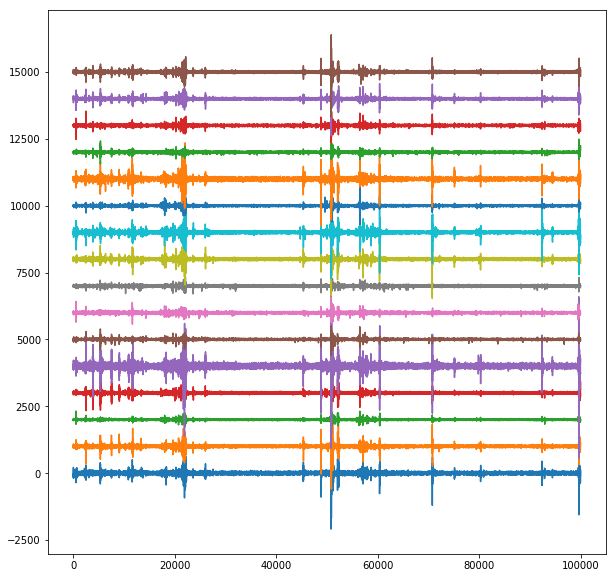

In [11]:
plt.figure(figsize=(10, 10))
plt.plot(filtered + np.arange(16) * 1000)
plt.show()

In [12]:
original_signal, predicted_signal = filter_data_by_blocks(X, n_lags, 1000)

In [13]:
fn = theano.function([X, n_lags], [original_signal, predicted_signal])

In [51]:
%timeit out1, out2 = fn(x, 9)

1 loop, best of 3: 13.3 s per loop


In [15]:
out1, out2 = fn(x, 11)

In [19]:
out1 = np.concatenate(out1)
out2 = np.concatenate(out2)

In [18]:
np.concatenate(out2).shape

(99000, 16)

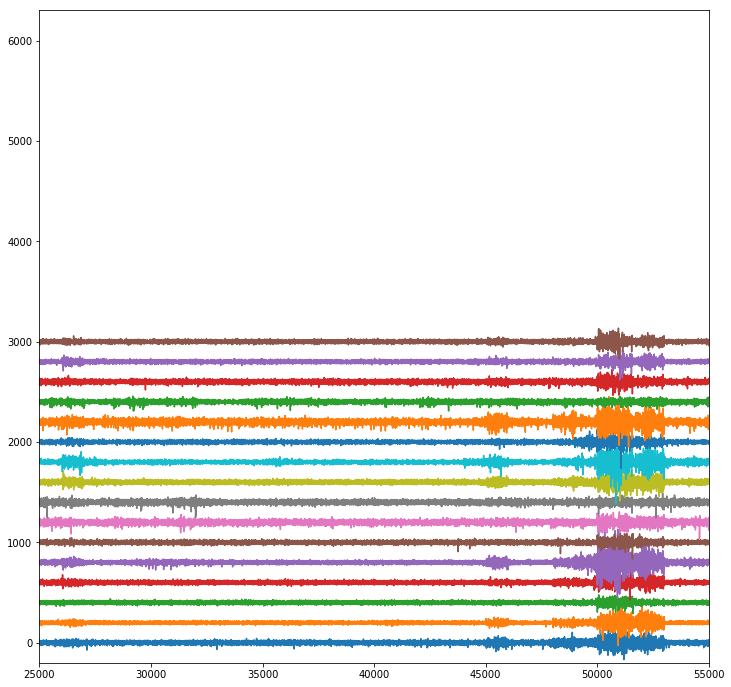

In [50]:
plt.figure(figsize=(12, 12))
plt.plot(out1 - out2 + np.arange(16) * 200)
# plt.plot(out1 + np.arange(16) * 700, alpha=0.7)# , color="Gray")
plt.ylim(-200, 6300)
plt.xlim(25000, 55000)
plt.show()

In [ ]:
class VectorRegression(object):
    X = T.fmatrix("input_batch")     # (n_samples, n_elec)
    n_lags = T.iscalar("n_lags")

    X_lagged, _ = theano.scan(
        fn=lambda idx, X: T.roll(X, idx, axis=0),
        sequences=T.arange(n_lags),
        non_sequences=[X])

    # (n_samples, n_elec, n_lags)
    X_lagged = X_lagged.dimshuffle(1, 2, 0)
    X_lagged_valid_range = X_lagged[n_lags-1:-1]

    Y = X[n_lags//2:-1-n_lags//2]
    X_reshaped = X_lagged_valid_range.reshape((X_lagged_valid_range.shape[0], -1))
    XX = T.dot(X_reshaped.T, X_reshaped)
    XY = T.dot(X_reshaped.T, Y)
    B = T.dot(T.nlinalg.pinv(XX), XY)
    
    _fit = theano.function([X, n_lags], B)
    _predict = theano.function([X, n_lags], T.dot(X_reshaped, B))
    
    def fit_predict(self, data, n_lags):
        return VectorRegression._predict(float_x(data), n_lags)